In [1]:
import pandas as pd
import numpy as np
import os
from glob import glob
from sklearn.metrics import roc_curve, auc, balanced_accuracy_score
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

In [19]:
#========== FUNCTIONS TO PRINT SCORES ==========#

def load_txt_file(rootpath, model_name):
    txt_path = os.path.join(rootpath, model_name, "scores.txt")
    if not os.path.exists(txt_path):
        raise FileNotFoundError(f"File not found: {txt_path}")

    scores = []
    labels = []
    with open(txt_path, 'r') as fh:
        for line in fh:
            parts = line.strip().split()
            if len(parts) != 3:
                continue  # skip malformed lines

            _, score, label = parts
            score = score.strip("[]")
            scores.append(float(score))
            labels.append(int(label))

    scores = np.array(scores)
    labels = np.array(labels)
    return scores, labels

def print_metrics(scores, labels):
    fpr, tpr, thres = roc_curve(labels, scores)
    rocauc = auc(fpr, tpr)
    fnr = 1 - tpr
    eer = fpr[np.nanargmin(np.absolute(fnr - fpr))]
    print(f"AUC: {rocauc * 100:.2f}%, EER: {eer * 100:.2f}%")
    
def plot_scores_distribution(scores, labels):
    # Split real/fake
    real_scores = scores[labels == 0]
    fake_scores = scores[labels == 1]

    print(f"Loaded {len(scores)} samples")
    print(f"Real mean score: {real_scores.mean():.4f}")
    print(f"Fake mean score: {fake_scores.mean():.4f}\n")

    # Plot
    plt.figure(figsize=(6, 4))
    plt.hist(real_scores, bins=100, alpha=0.5, density=True)
    plt.hist(fake_scores, bins=100, alpha=0.5, density=True)
    plt.xlabel("Score")
    plt.ylabel("Density")
    plt.title(f"Score Distribution")
    plt.legend(["Real (0)", "Fake (1)"])
    plt.show()

def plot_expert_stats(rootpath,
                      model_name,
                      stat="gating",
                      expert_labels=None):

    base_path = os.path.join(rootpath, model_name)

    global_path = os.path.join(base_path, f"{stat}_mean_global.npy")
    real_path   = os.path.join(base_path, f"{stat}_mean_real.npy")
    spoof_path  = os.path.join(base_path, f"{stat}_mean_fake.npy")

    global_w = np.load(global_path).flatten()
    real_w   = np.load(real_path).flatten()
    spoof_w  = np.load(spoof_path).flatten()

    if expert_labels is not None:
        n_experts = len(expert_labels)
        if len(global_w) != n_experts:
            raise ValueError(
                f"Mismatch: loaded stats have {len(global_w)} experts "
                f"but expert_labels has {n_experts}")
    else:
        n_experts = len(global_w)
        expert_labels = [f"E{i}" for i in range(n_experts)]

    fig, axes = plt.subplots(1, 3, figsize=(4*n_experts/2 + 6, 4), sharey=True)

    if stat == "gating":
        fig.suptitle("Gating Weights")
    elif stat == "weighted":
        fig.suptitle("Gating × Expert Probs")
    else:
        fig.suptitle("Expert Probs")

    titles = ["Avg global", "Avg real", "Avg fake"]
    data   = [global_w, real_w, spoof_w]
    colors = ["blue", "pink", "green"]

    for ax, weights, title, color in zip(axes, data, titles, colors):
        ax.bar(range(n_experts), weights, color=color)
        ax.set_title(title)
        ax.set_xticks(range(n_experts))
        ax.set_xticklabels(expert_labels, rotation=45)
        ax.set_ylim(0, 1)
        ax.grid(True)
        ax.set_axisbelow(True)

    axes[0].set_ylabel("Value")

    plt.tight_layout()
    plt.show()

    return data


In [29]:
def compute_res_and_plot(rootpath, model_name, expert_labels, distr=False, plot=True):
    scores, labels = load_txt_file(rootpath, model_name)
    
    print("\nIndividual Experts' Performance:")
    experts_scores = np.load(os.path.join(rootpath, model_name, "expert_all.npy"))
    for i in range(experts_scores.shape[1]):
        print_metrics(experts_scores[:, i], labels)    
    print("\nMoE Performance:")
    print_metrics(scores, labels)

    if distr:
        plot_scores_distribution(scores, labels)
        
    if plot:
        out_e = plot_expert_stats(rootpath, model_name, stat= 'expert', expert_labels=expert_labels)
        out_g = plot_expert_stats(rootpath, model_name, stat= 'gating', expert_labels=expert_labels)
        out_w = plot_expert_stats(rootpath, model_name, stat= 'weighted', expert_labels=expert_labels)
        return out_e, out_g, out_w

# Best model(s) so far
- 5 experts
- Frozen
- Trained using WxP 


Individual Experts' Performance:
AUC: 47.59%, EER: 51.90%
AUC: 30.90%, EER: 64.03%
AUC: 52.68%, EER: 50.01%
AUC: 77.23%, EER: 30.35%
AUC: 64.34%, EER: 41.87%

MoE Performance:
AUC: 58.38%, EER: 44.40%


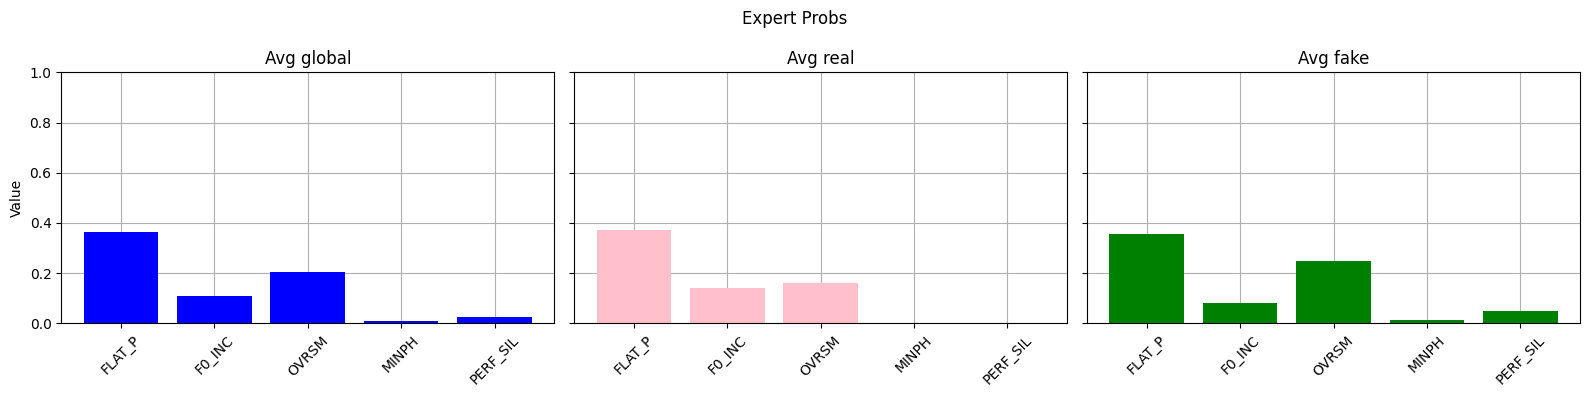

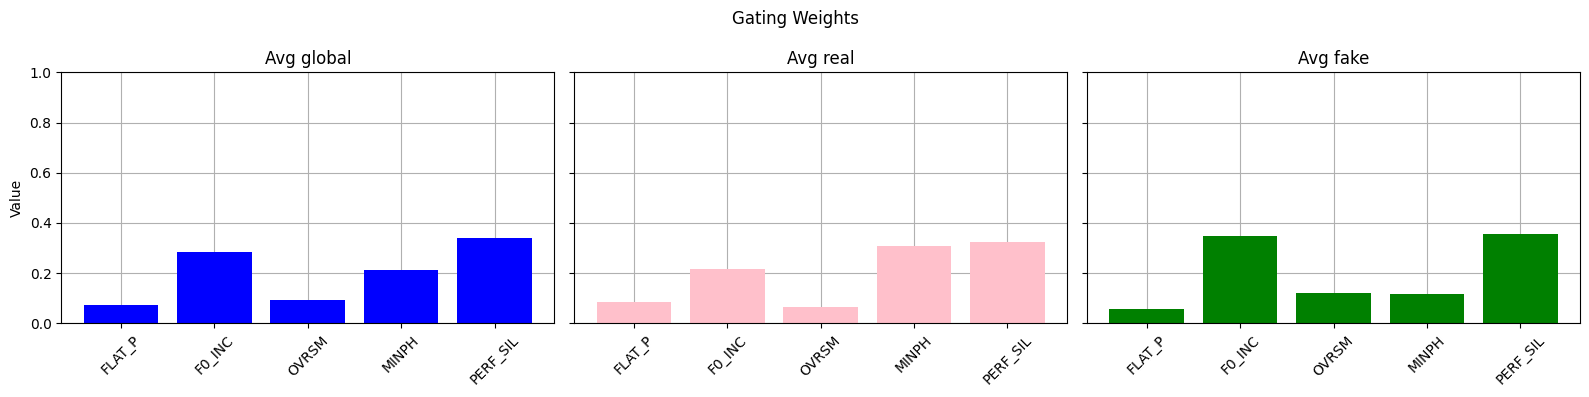

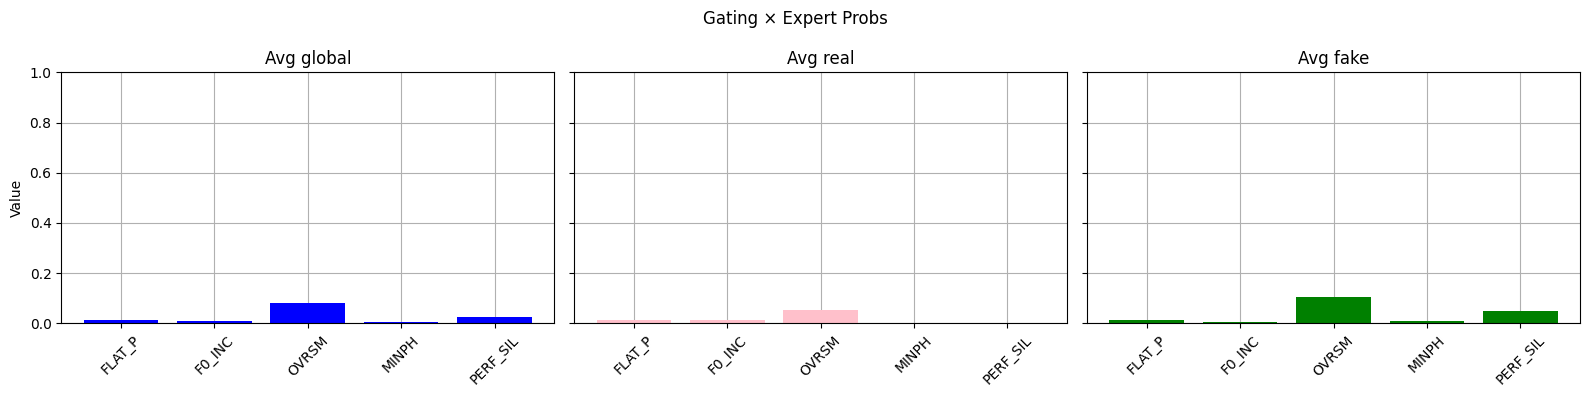

In [6]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/MoE/TargetCheck/ALL"
model_name = "frozen_5_experts_wxp"
expert_labels = ['FLAT_P', 'F0_INC', 'OVRSM', 'MINPH', 'PERF_SIL']
compute_res_and_plot(rootpath, model_name, expert_labels=expert_labels)

# Best model - per generator analysis

In [30]:
generator_list = ['A01', 'A02', 'A03', 'A04', 'A07',  'A08', 'A09', 'A10', 'A11', 'A12']
for g in generator_list:
    print(g)
    rootpath = f"/home/smg/v-viola/moe_antideepfake/results/MoE/TargetCheck/{g}"
    model_name = "frozen_5_experts_wxp"
    expert_labels = ['FLAT_P', 'F0_INC', 'OVRSM', 'MINPH', 'PERF_SIL']
    e, w, g, = compute_res_and_plot(rootpath, model_name, expert_labels=expert_labels, plot=False)
    print("-----------------------------------")

A01

Individual Experts' Performance:
AUC: 72.92%, EER: 31.99%
AUC: 32.78%, EER: 62.91%
AUC: 79.52%, EER: 30.07%
AUC: 73.13%, EER: 33.37%
AUC: 32.87%, EER: 62.49%

MoE Performance:
AUC: 73.70%, EER: 33.37%
-----------------------------------
A02

Individual Experts' Performance:
AUC: 31.26%, EER: 63.02%
AUC: 17.31%, EER: 73.75%
AUC: 66.08%, EER: 39.43%
AUC: 72.41%, EER: 34.75%
AUC: 61.48%, EER: 44.21%

MoE Performance:
AUC: 55.93%, EER: 47.08%
-----------------------------------
A03

Individual Experts' Performance:
AUC: 42.46%, EER: 56.11%
AUC: 22.00%, EER: 69.71%
AUC: 63.72%, EER: 40.60%
AUC: 88.08%, EER: 19.98%
AUC: 76.86%, EER: 30.71%

MoE Performance:
AUC: 56.30%, EER: 46.76%
-----------------------------------
A04

Individual Experts' Performance:
AUC: 63.55%, EER: 40.70%
AUC: 72.36%, EER: 34.43%
AUC: 41.74%, EER: 57.60%
AUC: 41.26%, EER: 56.11%
AUC: 74.05%, EER: 34.22%

MoE Performance:
AUC: 66.69%, EER: 35.92%
-----------------------------------
A07

Individual Experts' Perform

# Further diagnosis


Individual Experts' Performance:
AUC: 31.75%, EER: 63.55%
AUC: 13.62%, EER: 76.41%
AUC: 38.91%, EER: 58.77%
AUC: 83.97%, EER: 24.02%
AUC: 31.38%, EER: 64.08%

MoE Performance:
AUC: 42.43%, EER: 54.20%


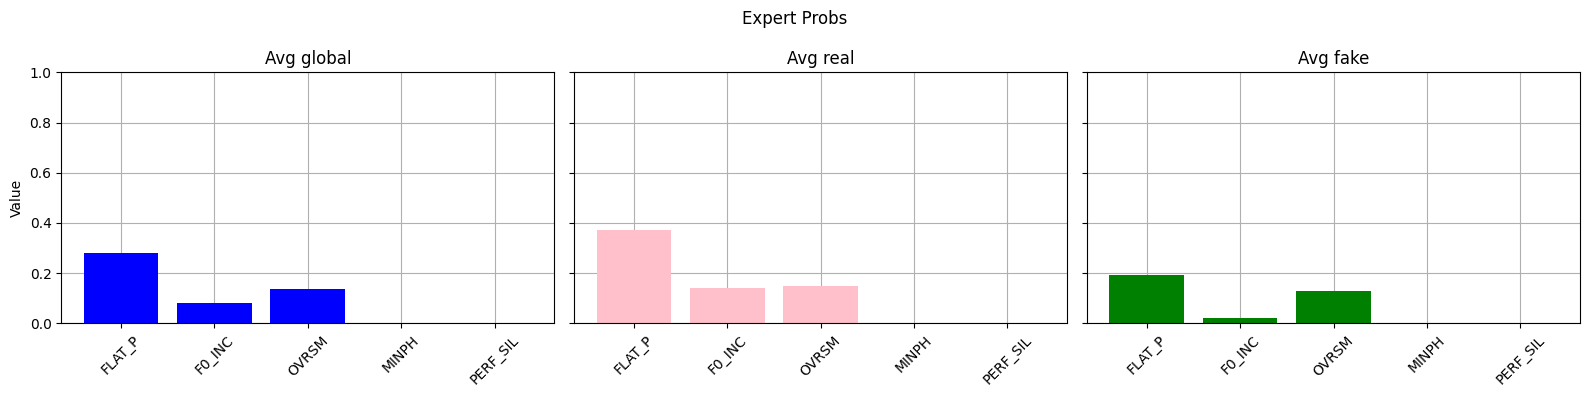

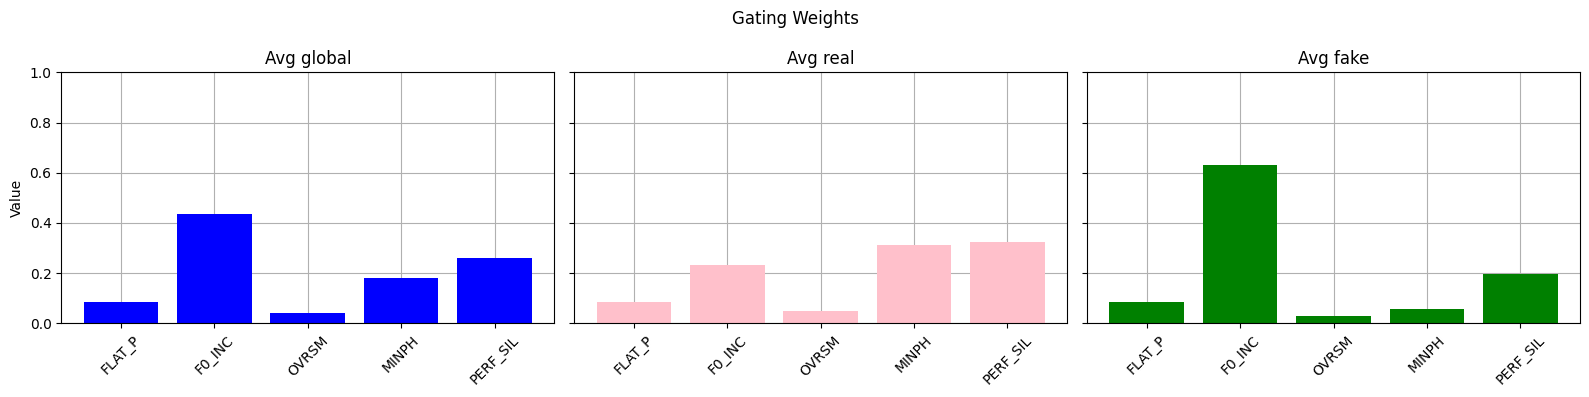

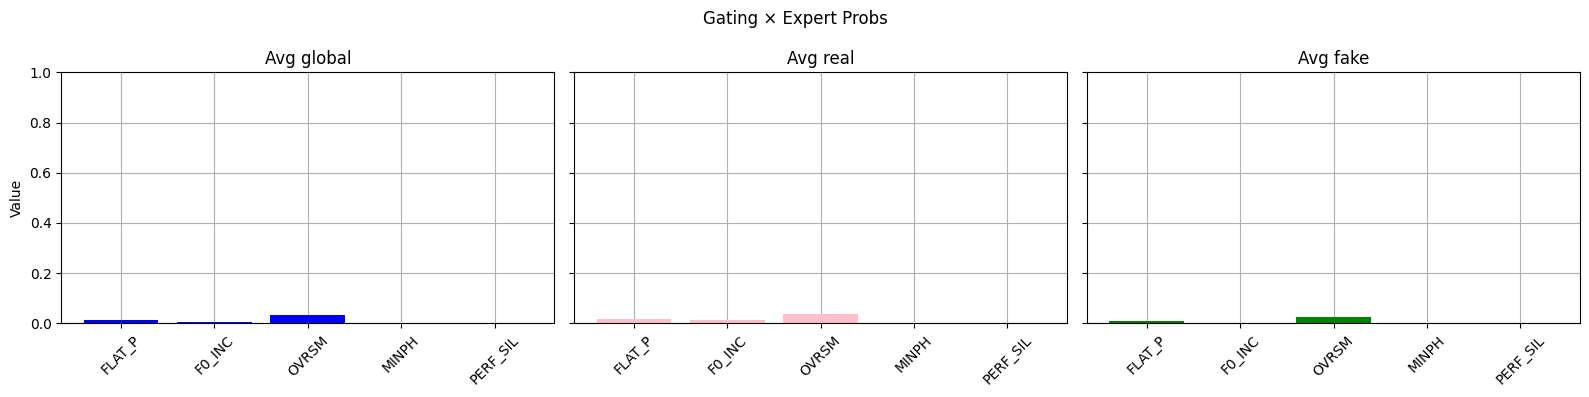

In [14]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/MoE/TargetCheck/A07"
model_name = "frozen_5_experts_wxp"
expert_labels = ['FLAT_P', 'F0_INC', 'OVRSM', 'MINPH', 'PERF_SIL']
e, w, g = compute_res_and_plot(rootpath, model_name, expert_labels=expert_labels, plot=True)

In [27]:
print("\nAverage Expert Stats + Gate Weights")
print("Expert |  Overall   |   Real     |   Fake     |  Δ(F-R)    | Gate_R  | Gate_F")
print("-" * 95)

for j in range(len(e[0])):
    overall = e[0][j]
    real = e[1][j]
    fake = e[2][j]
    delta = fake - real

    gate_real = w[1][j]
    gate_fake = w[2][j]

    print(f"{j:^6} | "
          f"{overall:10.6f} | "
          f"{real:10.6f} | "
          f"{fake:10.6f} | "
          f"{delta:10.6f} | "
          f"{gate_real:7.4f} | "
          f"{gate_fake:7.4f}")


Average Expert Stats + Gate Weights
Expert |  Overall   |   Real     |   Fake     |  Δ(F-R)    | Gate_R  | Gate_F
-----------------------------------------------------------------------------------------------
  0    |   0.280247 |   0.372598 |   0.193257 |  -0.179341 |  0.0840 |  0.0845
  1    |   0.079845 |   0.141239 |   0.022015 |  -0.119225 |  0.2307 |  0.6295
  2    |   0.138729 |   0.148154 |   0.129851 |  -0.018303 |  0.0507 |  0.0291
  3    |   0.000851 |   0.000019 |   0.001635 |   0.001616 |  0.3106 |  0.0583
  4    |   0.000000 |   0.000000 |   0.000000 |  -0.000000 |  0.3239 |  0.1986
